# P12: the training doctor

The brief asks for **training monitoring and failure diagnosis**. P02 to P08 read the learning curves (loss and accuracy):
they tell *that* a network trains badly, rarely *why*. This notebook looks inside the network while it trains, in the
spirit of TP05 and TP06: we make it fail on purpose, one failure at a time, read the symptoms, and check that the cure works.

`fit(..., monitor=True)` (in `utils.py`) records, without changing the training (checked bit for bit):

| measure | what it is | what a healthy value looks like |
|---|---|---|
| `batch_loss` | the loss of every batch | falls, with some noise; never explodes, never NaN |
| `grad_norm` | per layer with weights: mean norm of the gradient of its weights over an epoch | similar order of magnitude across layers |
| `update_ratio` | per layer: norm of (weights after the step - before) / norm of the weights before, mean over an epoch | about 1e-3 (a rule of thumb): 1e-5 barely learns, near 1 rewrites the layer at every step |
| `act_std` | per activation layer: spread of its outputs over the training images | stays of the same order from the first layer to the last |
| `dead` | per activation layer: share of its units that are never positive on any training image | 0: a dead ReLU outputs 0 and its weights get no gradient; it comes back only if the layers below change its inputs |
| `saturated` | per sigmoid / tanh layer: share of outputs stuck at the flat ends | small: there the gradient almost vanishes |

**The patient** is a dense network on the 32 x 32 images of P02 (3,072 numbers per image, standardised with the train
statistics), because one training run takes about a second. The P02 baseline is the healthy reference: one hidden layer of
128 ReLUs, Adam, learning rate 1e-3, batches of 64, 30 epochs, seed 0. Every patient changes **one thing** from a healthy
network. Plain SGD is used where the course uses it: Adam rescales every step by the size of past gradients, which hides some
failures (it keeps every ReLU of the baseline alive even at a learning rate of 1).

Only museum A (train and validation) is used. Nothing is saved in `results/` and museum B is never touched (ADR 0003): these
are diagnoses, not models. Scores are best epochs on 480 validation images (about +/- 4 points), one seed: read them as
"trains" or "does not train", not as a ranking.

In [1]:
import math

import matplotlib.pyplot as plt
import pandas as pd
import torch

from deep_learning_project_waerniers_lamy_mahieddine.vision.utils import (
    activation_stats, build_mlp, evaluate, fit, load_data, monitored_layers)

data = load_data(size=32)  # museum A only: train (1,920) and validation (480), standardised, flattened
EPOCHS = 30


def mlp(**config):
    """A dense network on 32 px images (build_mlp), always with the same starting weights (seed 0)."""
    torch.manual_seed(0)
    return build_mlp({"image_size": 32, **config})


def train(model, d=None, epochs=EPOCHS, **settings):
    """fit with the monitoring on, seed 0, silent. settings go to fit (lr, optimizer, clip_grad_norm...)."""
    return fit(model, data if d is None else d, epochs=epochs, seed=0, verbose=False, monitor=True, **settings)


def summary_row(result):
    """The few numbers that tell a healthy run from a sick one."""
    h = result["history"]
    finite = [x for x in h["batch_loss"] if math.isfinite(x)]
    first_layer = next(iter(h["grad_norm"]))
    return {
        "largest batch loss": max(finite) if finite else math.nan,
        "NaN loss": any(math.isnan(x) for x in h["batch_loss"]),
        "train loss, last epoch": h["train_loss"][-1],
        "train acc, last epoch": h["train_acc"][-1],
        "val acc, best epoch": result["best_val_acc"],
        "grad norm, layer 1, epoch 1": h["grad_norm"][first_layer][0],
        "update ratio, layer 1, epoch 1": h["update_ratio"][first_layer][0],
        "dead units, last epoch (worst layer)": max(v[-1] for v in h["dead"].values()),
    }


def table(results):
    return pd.DataFrame([summary_row(r) for r in results.values()], index=list(results))  # one row per run


print("train:", tuple(data["X_train"].shape), "| validation:", tuple(data["X_val"].shape))

train: (1920, 3072) | validation: (480, 3072)


## 1. Sanity checks before any diagnosis

Three checks that cost seconds and catch bugs that no tuning can fix (the data, the labels, the loss or the training loop):

1. **The loss before training.** With random weights and 5 balanced classes the network should guess uniformly: loss near
   ln 5 = 1.61, accuracy near 20%.
2. **Learn one batch by heart.** 64 images, many steps: a working network and training loop must reach 100% on them. If it
   cannot, something is broken, whatever the validation says.
3. **Random labels.** The genres of the training images are shuffled. A network with enough weights can still learn the
   training set by heart, but validation must stay at chance (20%): there is nothing to generalise. It measures how much the
   network can memorise, which is what P02's overfitting was about.

In [2]:
model = mlp(hidden=[128])  # the P02 baseline: same layers, same starting weights
loss0, acc0 = evaluate(model, data["X_train"], data["y_train"])
print(f"before training: loss {loss0:.3f} (ln 5 = {math.log(5):.3f}), accuracy {acc0:.1%} (chance 20%)")

before training: loss 1.639 (ln 5 = 1.609), accuracy 16.4% (chance 20%)


In [3]:
batch = torch.randperm(len(data["X_train"]), generator=torch.Generator().manual_seed(0))[:64]
one_batch = dict(data, X_train=data["X_train"][batch], y_train=data["y_train"][batch])
one = train(mlp(hidden=[128]), one_batch, epochs=100)  # a single batch, so one epoch is one step
h = one["history"]
first_perfect = next(e + 1 for e, acc in enumerate(h["train_acc"]) if acc == 1.0)
print(f"one batch of 64 images: 100% train accuracy first reached after {first_perfect} steps, "
      f"loss after 100 steps {h['train_loss'][-1]:.4f}; validation {h['val_acc'][-1]:.1%} (it learnt 64 images, nothing more)")

one batch of 64 images: 100% train accuracy first reached after 7 steps, loss after 100 steps 0.0003; validation 27.7% (it learnt 64 images, nothing more)


after shuffling, 19.6% of the training labels are still right (chance: 20%)


                           train acc, last epoch  val acc, best epoch  \
true labels, 200 epochs                      1.0                0.392   
random labels, 200 epochs                    1.0                0.233   

                           train loss, last epoch  
true labels, 200 epochs                       0.0  
random labels, 200 epochs                     0.0  
random labels, validation over the last 50 epochs: mean 19.0%


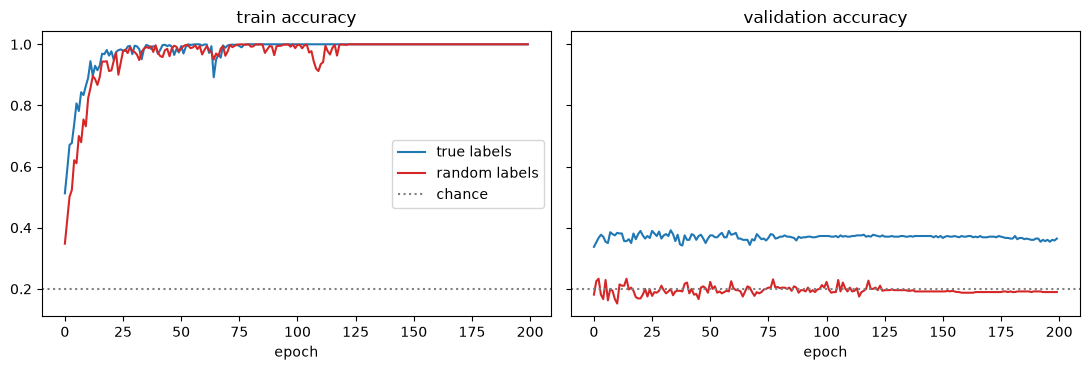

In [4]:
shuffled = torch.randperm(len(data["y_train"]), generator=torch.Generator().manual_seed(1))
random_labels = dict(data, y_train=data["y_train"][shuffled])
agreement = (random_labels["y_train"] == data["y_train"]).float().mean().item()
print(f"after shuffling, {agreement:.1%} of the training labels are still right (chance: 20%)")

true_run = train(mlp(hidden=[128]), epochs=200)
random_run = train(mlp(hidden=[128]), random_labels, epochs=200)
print(table({"true labels, 200 epochs": true_run, "random labels, 200 epochs": random_run})
      [["train acc, last epoch", "val acc, best epoch", "train loss, last epoch"]].round(3))
print(f"random labels, validation over the last 50 epochs: mean {pd.Series(random_run['history']['val_acc'][-50:]).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, split in zip(axes, ["train_acc", "val_acc"]):
    ax.plot(true_run["history"][split], label="true labels", color="tab:blue")
    ax.plot(random_run["history"][split], label="random labels", color="tab:red")
    ax.axhline(0.2, color="grey", linestyle=":", label="chance")
    ax.set_title("train accuracy" if split == "train_acc" else "validation accuracy")
    ax.set_xlabel("epoch")
axes[0].legend()
plt.tight_layout()
plt.show()

**What we see.**

- **The start is right:** loss 1.639 against ln 5 = 1.609, accuracy 16.4%: the untrained network guesses, as in P02.
- **The training loop works:** one batch of 64 images is learnt by heart after 7 steps (loss 0.0003 after 100 steps). Validation stays at 27.7%: 64 images teach nothing general.
- **The network can memorise anything.** With shuffled labels (19.6% of them still right by chance) it still reaches 100% train accuracy, while validation stays at chance (19.0% on average over the last 50 epochs; 23.3% at its best epoch, a lucky peak). With the true labels it also reaches 100% train, and 39.2% validation.
- So for this network a high train accuracy proves nothing: its 394k weights can store 1,920 images whatever their labels. P02's 98% train against 39% validation is memorisation, not a training bug. The cure is fewer free weights or regularisation (next notebook), not more or better training.

## 2. Patient 1: the learning rate

The same network and optimiser (Adam) as the baseline, with learning rates from 1 to 1e-5 (the baseline uses 1e-3). What we
watch: the loss of every batch (too high: it explodes or jumps around), and the update ratio of the first layer (rule of
thumb: about 1e-3 per step).

In [5]:
LEARNING_RATES = [1, 1e-1, 1e-2, 1e-3, 1e-4, 1e-5]
lr_runs = {lr: train(mlp(hidden=[128]), lr=lr) for lr in LEARNING_RATES}
table({f"lr {lr:g}": r for lr, r in lr_runs.items()}).round(4)

,largest batch loss,NaN loss,"train loss, last epoch","train acc, last epoch","val acc, best epoch","grad norm, layer 1, epoch 1","update ratio, layer 1, epoch 1","dead units, last epoch (worst layer)"
lr 1,77561.5703,False,11833.3204,0.6042,0.3542,170.4456,3.3609,0.0
lr 0.1,622.9759,False,48.4824,0.6792,0.3500,12.8937,0.4625,0.0
lr 0.01,14.5423,False,0.7783,0.8641,0.3854,3.2474,0.1249,0.0
lr 0.001,1.8989,False,0.1465,0.9677,0.3896,2.9444,0.0273,0.0
lr 0.0001,1.6371,False,0.4858,0.8922,0.4000,2.4464,0.0037,0.0
lr 1e-05,1.6497,False,1.1422,0.5740,0.3521,2.8609,0.0005,0.0


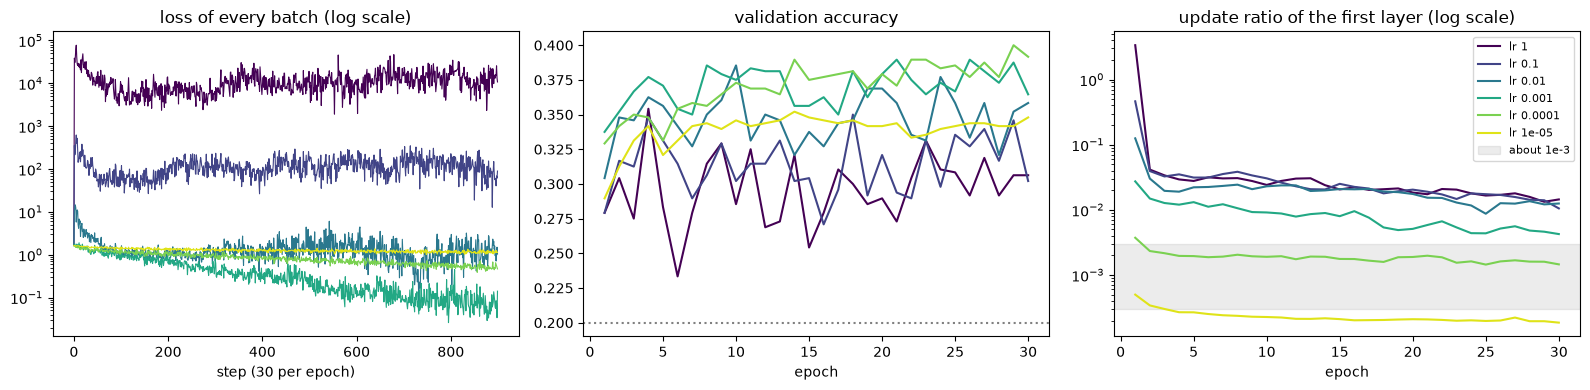

In [6]:
colors = dict(zip(LEARNING_RATES, plt.cm.viridis([0.0, 0.2, 0.4, 0.6, 0.8, 0.95])))  # one colour per learning rate, in order
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for lr, r in lr_runs.items():
    h = r["history"]
    axes[0].plot(h["batch_loss"], color=colors[lr], label=f"lr {lr:g}", linewidth=0.8)
    axes[1].plot(range(1, EPOCHS + 1), h["val_acc"], color=colors[lr], label=f"lr {lr:g}")
    axes[2].plot(range(1, EPOCHS + 1), h["update_ratio"]["0"], color=colors[lr], label=f"lr {lr:g}")
axes[0].set_yscale("log")
axes[0].set_title("loss of every batch (log scale)")
axes[0].set_xlabel("step (30 per epoch)")
axes[1].axhline(0.2, color="grey", linestyle=":")
axes[1].set_title("validation accuracy")
axes[1].set_xlabel("epoch")
axes[2].set_yscale("log")
axes[2].axhspan(3e-4, 3e-3, color="grey", alpha=0.15, label="about 1e-3")
axes[2].set_title("update ratio of the first layer (log scale)")
axes[2].set_xlabel("epoch")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

**What we see.**

- **Too high (1 and 0.1): the loss explodes.** The batch loss jumps from 1.6 to 77,562 (lr 1) and 623 (lr 0.1) in the first steps and never comes back (train loss at the last epoch: 11,833 and 48). At the first epoch the update ratio of the first layer is 3.4 and 0.46: every step rewrites the layer. Validation jumps between 23% and 35% from one epoch to the next.
- **Too low (1e-5): the network barely moves.** Update ratio 5e-4 at the first epoch, 2e-4 at the end; train loss from 1.64 to 1.14 in 30 epochs (57% train accuracy).
- **1e-3 (the baseline) and 1e-4 are healthy:** the loss falls steadily and the update ratio settles at 4e-3 and 1.5e-3, close to the 1e-3 rule of thumb. 1e-2 is borderline (1.2e-2 at the end, a noisy batch loss).
- **The update ratio diagnoses the learning rate without looking at validation**, from the first epoch: it is the cheapest check of all.
- **Adam hides the dead-ReLU failure:** no ReLU of this network died at any learning rate, even at 1 with a loss of 10,000. Adam divides each step by the size of the recent gradients. The next patients use plain SGD, as in the course.
- For the next notebook (one seed, inside the +/- 4 points): lr 1e-4 reaches 40.0% at epoch 29, still rising, against 39.0% at 1e-3. Worth testing with 5 seeds.

## 3. Patient 2: the inputs are not standardised

Every model of the project standardises the pixels with the mean and std of the train images (`load_data`). Here we undo it:
the raw pixels from 0 to 255 (as read from the file), and the pixels scaled to 0-1 (divided by 255, not centred). Plain SGD,
the baseline network, five learning rates for each. Why it should matter (course, session 3): with large, all-positive
inputs the loss is a long, narrow valley; the gradient points across the valley, not along it, and a learning rate small
enough not to explode is too small to move along it.

In [7]:
mean = torch.tensor(data["mean"]).repeat(32 * 32)  # a flat row is pixel after pixel, 3 channels each
std = torch.tensor(data["std"]).repeat(32 * 32)
pixels_0_1 = {k: data[k] * std + mean for k in ["X_train", "X_val"]}  # undo the standardisation
inputs = {
    "0-255": dict(data, **{k: x * 255 for k, x in pixels_0_1.items()}),
    "0-1": dict(data, **pixels_0_1),
    "standardised": data,
}
for name, d in inputs.items():
    x = d["X_train"]
    print(f"{name:13s} inputs: min {x.min().item():7.2f}, max {x.max().item():7.2f}, mean {x.mean().item():7.2f}, std {x.std().item():6.2f}")

SGD_RATES = [1e-1, 1e-2, 1e-3, 1e-4, 1e-5]
input_runs = {(name, lr): train(mlp(hidden=[128]), d, lr=lr, optimizer="sgd") for name, d in inputs.items() for lr in SGD_RATES}
rows = table({f"{name}, lr {lr:g}": r for (name, lr), r in input_runs.items()})
print("best validation accuracy (rows: inputs, columns: learning rate):")
best = pd.DataFrame({lr: {name: input_runs[(name, lr)]["best_val_acc"] for name in inputs} for lr in SGD_RATES})
print(best.round(3))
rows[["largest batch loss", "train loss, last epoch", "grad norm, layer 1, epoch 1", "dead units, last epoch (worst layer)"]].round(3)

0-255         inputs: min    0.00, max  255.00, mean  114.99, std  60.29
0-1           inputs: min    0.00, max    1.00, mean    0.45, std   0.24
standardised  inputs: min   -2.15, max    2.72, mean   -0.00, std   1.00


best validation accuracy (rows: inputs, columns: learning rate):
              0.10000  0.01000  0.00100  0.00010  0.00001
0-255           0.200    0.200    0.202    0.365    0.338
0-1             0.360    0.346    0.319    0.229    0.181
standardised    0.402    0.390    0.344    0.323    0.235


,largest batch loss,"train loss, last epoch","grad norm, layer 1, epoch 1","dead units, last epoch (worst layer)"
"0-255, lr 0.1",4.686506e+07,1.609,147916.246,1.000
"0-255, lr 0.01",2.072416e+05,1.609,2884.489,1.000
"0-255, lr 0.001",3.567107e+03,1.607,331.439,0.953
"0-255, lr 0.0001",2.293230e+02,1.207,298.880,0.258
"0-255, lr 1e-05",2.523900e+01,2.138,923.247,0.039
"0-1, lr 0.1",1.849000e+00,1.181,1.025,0.453
"0-1, lr 0.01",1.629000e+00,1.265,1.267,0.031
"0-1, lr 0.001",1.639000e+00,1.500,1.383,0.023
"0-1, lr 0.0001",1.641000e+00,1.591,1.460,0.023
"0-1, lr 1e-05",1.647000e+00,1.615,1.473,0.023


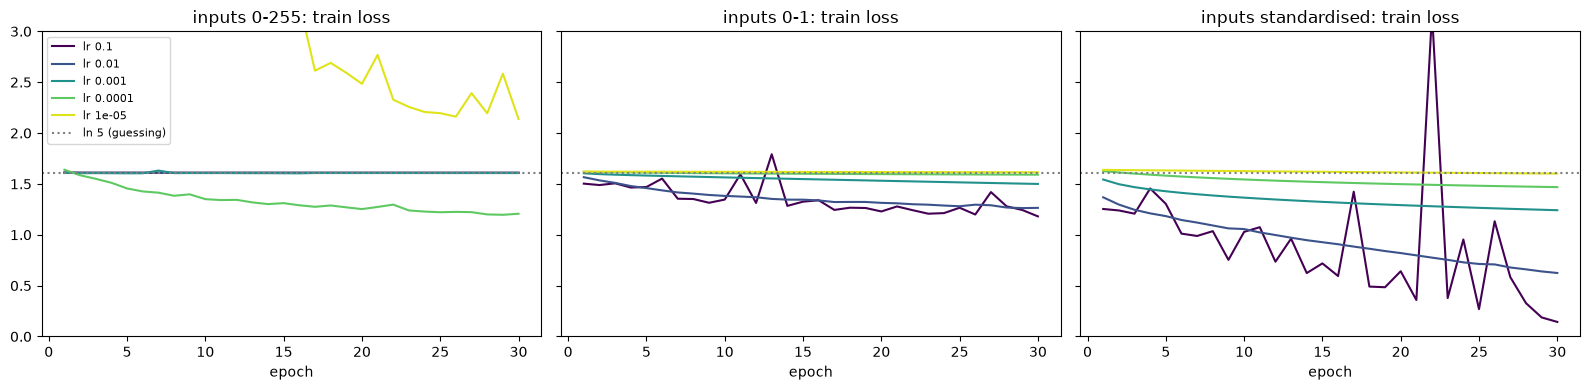

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, name in zip(axes, inputs):
    for lr, color in zip(SGD_RATES, plt.cm.viridis([0.0, 0.25, 0.5, 0.75, 0.95])):
        ax.plot(range(1, EPOCHS + 1), input_runs[(name, lr)]["history"]["train_loss"], color=color, label=f"lr {lr:g}")
    ax.axhline(math.log(5), color="grey", linestyle=":", label="ln 5 (guessing)")
    ax.set_title(f"inputs {name}: train loss")
    ax.set_xlabel("epoch")
    ax.set_ylim(0, 3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Treat the cause, not the symptom

On the raw 0-255 inputs (SGD, learning rate 1e-3), three possible "cures": a leaky ReLU (a dead unit still lets 1% of the
gradient through), gradient clipping at norm 1, and the real cause removed, standardised inputs.

In [9]:
cures = {
    "0-255, ReLU (the patient)": input_runs[("0-255", 1e-3)],
    "0-255, leaky ReLU": train(mlp(hidden=[128], activation="leaky_relu"), inputs["0-255"], lr=1e-3, optimizer="sgd"),
    "0-255, ReLU, clipping at 1": train(mlp(hidden=[128]), inputs["0-255"], lr=1e-3, optimizer="sgd", clip_grad_norm=1.0),
    "standardised, ReLU": input_runs[("standardised", 1e-3)],
}
table(cures)[["largest batch loss", "train loss, last epoch", "val acc, best epoch", "dead units, last epoch (worst layer)"]].round(3)

,largest batch loss,"train loss, last epoch","val acc, best epoch","dead units, last epoch (worst layer)"
"0-255, ReLU (the patient)",3567.107,1.607,0.202,0.953
"0-255, leaky ReLU",527633.125,2070.001,0.281,0.766
"0-255, ReLU, clipping at 1",27.104,3.909,0.308,0.031
"standardised, ReLU",1.652,1.242,0.344,0.000


**What we see.**

- **Raw pixels (0-255) kill the network.** The gradient of the first layer is huge at the first epoch (300 to 150,000, against 2.5 to 3.2 with standardised inputs). With a learning rate of 1e-3 or more, the first steps blow the network up (batch loss up to 47 million at lr 0.1), and 95 to 100% of the ReLUs end dead: every image then gives the same output, the train loss sits at ln 5 = 1.609 and validation at 20%. Only lr 1e-4 and 1e-5 survive, and they learn less (validation 36.5% and 33.8%; train loss 1.21 and 2.14).
- **Pixels in 0-1, not centred, do not explode but learn slowly:** after 30 epochs the train loss is at best 1.18 (lr 0.1), against 0.14 with standardised inputs at the same learning rate, and validation is behind at every learning rate (36.0 / 34.6 / 31.9 / 22.9 / 18.1% against 40.2 / 39.0 / 34.4 / 32.3 / 23.5%). With all-positive inputs, the gradients of all the weights of a neuron have the same sign at each step: they can only all go up or all go down, which forces a zigzag.
- **Standardised inputs train best at every learning rate, and no ReLU dies.**
- **The cures:** a leaky ReLU does not cure anything (the loss explodes even more, to 527,633, and is still 2,070 at the end). Clipping at 1 keeps the units alive (3% dead) and gets 30.8%, with a train loss stuck at 3.9. Removing the cause, standardised inputs, gives 34.4% with the same learning rate and nothing else changed. Clipping and leaky ReLUs treat symptoms; the cause was the scale of the inputs.

## 4. Patient 3: depth and the activation function

Six hidden layers of 128 instead of one, PyTorch's default initialisation, plain SGD at two learning rates, and four
activations: sigmoid, tanh, ReLU and leaky ReLU. We look at the gradient norm of each layer at the first epoch.

The course's argument: in backpropagation the gradient of an early layer is a product with one factor per layer above it,
and each factor contains the derivative of the activation. The derivative of a sigmoid is at most 0.25 (checked below with
autograd, as in TP05), so through 6 sigmoids the gradient can shrink by up to 0.25^6.

In [10]:
z = torch.linspace(-6, 6, 1201, requires_grad=True)
torch.sigmoid(z).sum().backward()
print(f"largest derivative of the sigmoid: {z.grad.max().item():.3f} (at z = {z[z.grad.argmax()].item():.1f}); "
      f"0.25^6 = {0.25 ** 6:.1e}")

ACTIVATIONS = ["sigmoid", "tanh", "relu", "leaky_relu"]
depth_runs = {(act, lr): train(mlp(hidden=[128] * 6, activation=act), lr=lr, optimizer="sgd")
              for act in ACTIVATIONS for lr in [0.01, 0.1]}
rows = table({f"{act}, lr {lr:g}": r for (act, lr), r in depth_runs.items()})
for (act, lr), r in depth_runs.items():
    g = list(r["history"]["grad_norm"].values())
    rows.loc[f"{act}, lr {lr:g}", "grad norm, layer 1 / last layer, epoch 1"] = g[0][0] / g[-1][0]
rows[["train loss, last epoch", "val acc, best epoch", "grad norm, layer 1 / last layer, epoch 1",
      "dead units, last epoch (worst layer)"]].round(4)

largest derivative of the sigmoid: 0.250 (at z = 0.0); 0.25^6 = 2.4e-04


,"train loss, last epoch","val acc, best epoch","grad norm, layer 1 / last layer, epoch 1","dead units, last epoch (worst layer)"
"sigmoid, lr 0.01",1.6097,0.2000,0.0001,0.0000
"sigmoid, lr 0.1",1.6223,0.2000,0.0001,0.0000
"tanh, lr 0.01",1.2708,0.3167,3.3200,0.0000
"tanh, lr 0.1",0.3445,0.3625,2.0953,0.0000
"relu, lr 0.01",1.5971,0.3062,0.8930,0.3828
"relu, lr 0.1",0.7701,0.3750,0.9154,0.1016
"leaky_relu, lr 0.01",1.5967,0.3062,0.8945,0.3750
"leaky_relu, lr 0.1",0.6578,0.3688,0.9192,0.1094


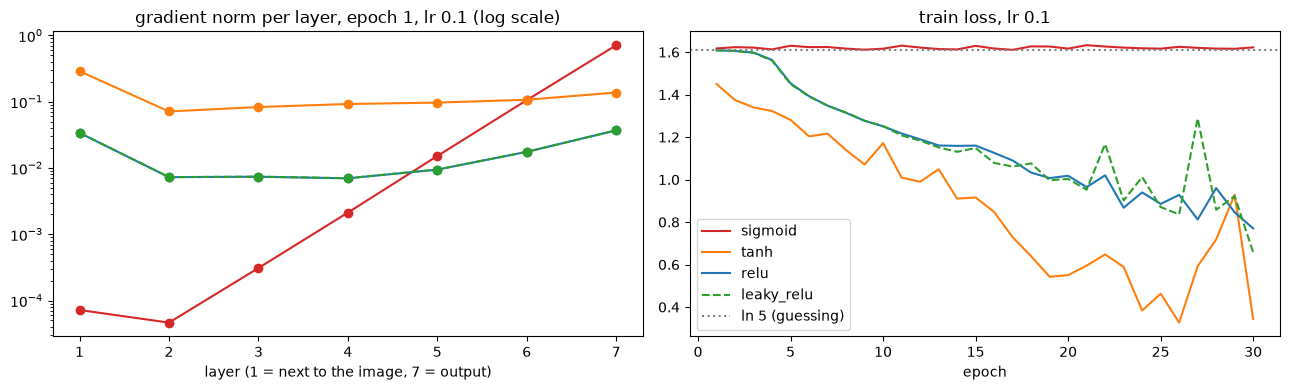

In [11]:
act_colors = dict(zip(ACTIVATIONS, ["tab:red", "tab:orange", "tab:blue", "tab:green"]))  # one colour per activation
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for act in ACTIVATIONS:
    g = depth_runs[(act, 0.1)]["history"]["grad_norm"]
    style = "--" if act == "leaky_relu" else "-"  # leaky ReLU lies on top of ReLU: dashed to see both
    axes[0].plot(range(1, len(g) + 1), [v[0] for v in g.values()], marker="o", color=act_colors[act], linestyle=style, label=act)
    axes[1].plot(range(1, EPOCHS + 1), depth_runs[(act, 0.1)]["history"]["train_loss"], color=act_colors[act], linestyle=style,
                 label=act)
axes[0].set_yscale("log")
axes[0].set_title("gradient norm per layer, epoch 1, lr 0.1 (log scale)")
axes[0].set_xlabel("layer (1 = next to the image, 7 = output)")
axes[1].axhline(math.log(5), color="grey", linestyle=":", label="ln 5 (guessing)")
axes[1].set_title("train loss, lr 0.1")
axes[1].set_xlabel("epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

### Dead ReLUs

A ReLU unit whose input is negative for every image outputs 0 and its own weights receive no gradient: it can only come back
if the layers below it change its inputs. A step that is far too large can push many units there at once. (A leaky ReLU passes
1% of the gradient for negative inputs, so its "never positive" units are not dead.) The same 6-layer network with plain SGD at a learning rate of 1.

In [12]:
dead_runs = {act: train(mlp(hidden=[128] * 6, activation=act), lr=1.0, optimizer="sgd") for act in ["relu", "leaky_relu"]}
for act, r in dead_runs.items():
    step = next((i + 1 for i, x in enumerate(r["history"]["batch_loss"]) if math.isnan(x)), None)
    print(f"{act}: first NaN loss at step {step} (epoch {-(-step // 30)})" if step else f"{act}: no NaN")
# once the weights are NaN every unit counts as "never positive", so we read the epochs before the explosion
dead = pd.DataFrame({f"{act}, epoch {e}": [round(v[e - 1], 2) for v in r["history"]["dead"].values()]
                     for act, r in dead_runs.items() for e in (1, 5, 12)},
                    index=[f"hidden layer {i}" for i in range(1, 7)])
print("\nshare of units never positive on any training image:")
print(dead)
table(dead_runs)[["largest batch loss", "NaN loss", "val acc, best epoch"]]

relu: first NaN loss at step 758 (epoch 26)
leaky_relu: first NaN loss at step 388 (epoch 13)

share of units never positive on any training image:
                relu, epoch 1  relu, epoch 5  relu, epoch 12  \
hidden layer 1           0.00           0.00            0.00   
hidden layer 2           0.00           0.05            0.05   
hidden layer 3           0.02           0.00            0.00   
hidden layer 4           0.05           0.06            0.03   
hidden layer 5           0.15           0.28            0.11   
hidden layer 6           0.30           0.72            0.79   

                leaky_relu, epoch 1  leaky_relu, epoch 5  leaky_relu, epoch 12  
hidden layer 1                 0.00                 0.00                  0.00  
hidden layer 2                 0.00                 0.03                  0.01  
hidden layer 3                 0.02                 0.00                  0.02  
hidden layer 4                 0.03                 0.09                  0.06 

,largest batch loss,NaN loss,"val acc, best epoch"
relu,9.731119e+10,True,0.337500
leaky_relu,2.490491e+07,True,0.310417


**What we see.**

- **Deep sigmoid: the gradient vanishes.** The largest derivative of the sigmoid is 0.250 (autograd). At the first epoch the gradient of the first layer is 10,000 times smaller than the gradient of the output layer (ratio 1e-4, the order of the 0.25^6 = 2.4e-4 bound). The early layers do not learn: the loss stays at ln 5 (1.61) and validation at 20%, at both learning rates. No output is saturated (0%): the gradient shrinks because each sigmoid multiplies it by 0.25 at most, not because the units are stuck.
- **tanh and ReLU keep the gradient alive:** the first layer gets 2 to 3 times (tanh) or 0.9 times (ReLU) the gradient of the last, and the networks train (train loss 0.34 for tanh, 0.77 for ReLU, 0.66 for leaky ReLU at lr 0.1). Validation stays between 36% and 38%: six layers do not beat the one-layer baseline (39%). Depth does not cure the memorisation of section 1.
- **Leaky ReLU behaves like ReLU here:** same gradients, same scores (its dashed lines lie on ReLU's).
- **Dead ReLUs at lr 1:** from the first epoch, 30% of the ReLUs of the last hidden layer never fire; by epoch 5 it is 72% (and 28% of the fifth layer), 79% at epoch 12. The loss explodes to NaN at step 758 (epoch 26) for ReLU and at step 388 (epoch 13) for leaky ReLU. Leaky ReLU does not prevent the explosion: the cause is the learning rate. Dead units can come back (the last layer goes back down to 46% at epoch 25) because the layers below them keep changing.

## 5. Patient 4: the initialisation, and gradient clipping

Ten hidden layers of 256 ReLUs. Before any training, we pass the training images through and measure the spread of each
layer's outputs (`act_std`): it should stay of the same order from the first layer to the last. Four ways to draw the first
weights: a normal with std 0.01 (too small), a normal with std 1 (too large), PyTorch's default, and He (Kaiming), which
scales the std by sqrt(2 / number of inputs) to compensate the half of the signal a ReLU cuts. Then each is trained with plain
SGD (learning rate 0.01).

In [13]:
INITS = {"normal, std 0.01": 0.01, "normal, std 1": 1.0, "PyTorch default": "default", "He (Kaiming)": "he"}
init_colors = dict(zip(INITS, ["tab:purple", "tab:red", "tab:orange", "tab:blue"]))
init_styles = dict(zip(INITS, [":", "-", "--", "-"]))  # two of them lie on the same flat line at ln 5
spread = {}
for label, init in INITS.items():
    model = mlp(hidden=[256] * 10, init=init)
    spread[label] = [s["act_std"] for s in activation_stats(monitored_layers(model)[1], model, data["X_train"]).values()]
print("spread of the outputs of each hidden layer, before training:")
print(pd.DataFrame(spread, index=range(1, 11)).T.map(lambda v: f"{v:.1e}"))

init_runs = {label: train(mlp(hidden=[256] * 10, init=init), lr=0.01, optimizer="sgd") for label, init in INITS.items()}
table(init_runs)[["NaN loss", "train loss, last epoch", "val acc, best epoch", "grad norm, layer 1, epoch 1",
                  "dead units, last epoch (worst layer)"]]

spread of the outputs of each hidden layer, before training:
                       1        2        3        4        5        6   \
normal, std 0.01  3.3e-01  3.8e-02  4.3e-03  4.6e-04  5.4e-05  6.0e-06   
normal, std 1     3.3e+01  3.8e+02  4.3e+03  4.6e+04  5.4e+05  6.0e+06   
PyTorch default   3.4e-01  1.4e-01  6.0e-02  3.2e-02  2.7e-02  2.4e-02   
He (Kaiming)      8.4e-01  8.5e-01  8.6e-01  8.1e-01  8.3e-01  8.2e-01   

                       7        8        9        10  
normal, std 0.01  6.6e-07  7.1e-08  8.0e-09  9.6e-10  
normal, std 1     6.6e+07  7.1e+08  8.0e+09  9.6e+10  
PyTorch default   2.1e-02  2.2e-02  2.2e-02  2.4e-02  
He (Kaiming)      8.0e-01  7.6e-01  7.6e-01  8.1e-01  


,NaN loss,"train loss, last epoch","val acc, best epoch","grad norm, layer 1, epoch 1","dead units, last epoch (worst layer)"
"normal, std 0.01",False,1.609438,0.2,5.943408e-10,1.000000
"normal, std 1",True,NaN,0.2,NaN,1.000000
PyTorch default,False,1.609437,0.2,8.174870e-04,0.523438
He (Kaiming),False,0.109727,0.4,5.429800e+00,0.031250


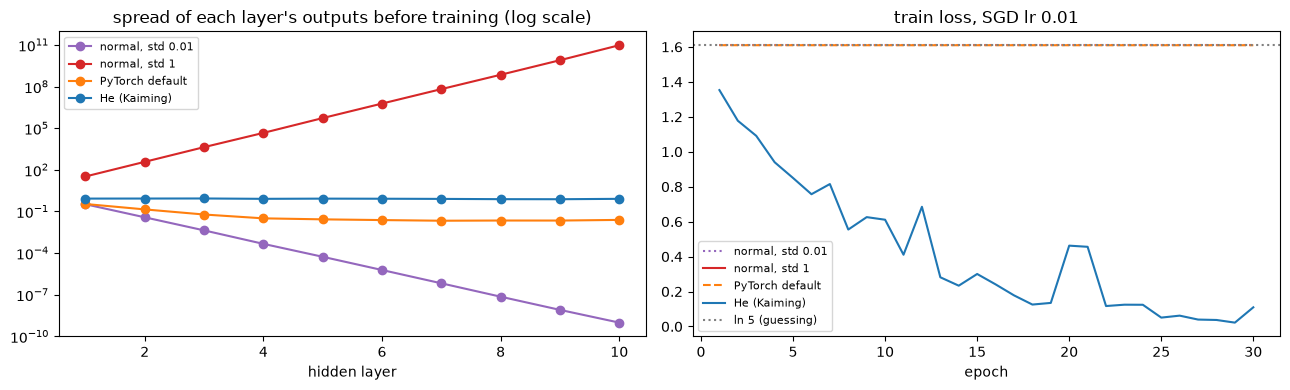

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for label in INITS:
    axes[0].plot(range(1, 11), spread[label], marker="o", color=init_colors[label], label=label)
    loss = init_runs[label]["history"]["train_loss"]
    axes[1].plot(range(1, EPOCHS + 1), loss, color=init_colors[label], linestyle=init_styles[label],
                 label=label)  # NaN epochs are not drawn: "normal, std 1" has no line
axes[0].set_yscale("log")
axes[0].set_title("spread of each layer's outputs before training (log scale)")
axes[0].set_xlabel("hidden layer")
axes[0].legend(fontsize=8)
axes[1].axhline(math.log(5), color="grey", linestyle=":", label="ln 5 (guessing)")
axes[1].set_title("train loss, SGD lr 0.01")
axes[1].set_xlabel("epoch")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Gradient clipping

Back to the 6-layer ReLU network of section 4 with plain SGD at a learning rate of 1, which ended in NaN. Gradient clipping
rescales the whole gradient to a maximum norm before each step (`clip_grad_norm`), so one bad batch cannot throw the weights
far away. Norms of the first layer's gradient are measured before clipping.

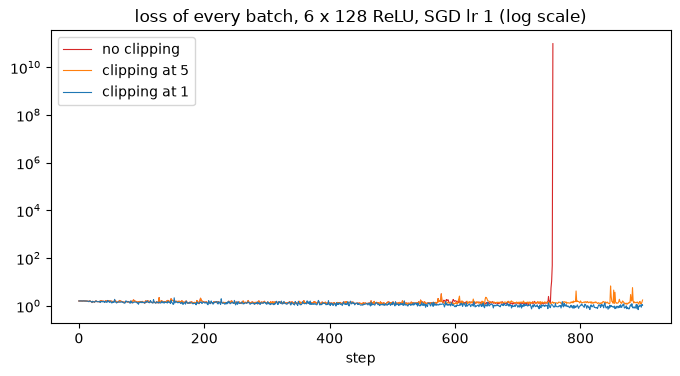

,largest batch loss,NaN loss,"train loss, last epoch","val acc, best epoch","dead units, last epoch (worst layer)"
no clipping,9.731119e+10,True,NaN,0.338,1.000
clipping at 5,6.852000e+00,False,1.384,0.338,0.500
clipping at 1,2.186000e+00,False,0.941,0.410,0.055


In [15]:
clip_runs = {"no clipping": dead_runs["relu"],
             "clipping at 5": train(mlp(hidden=[128] * 6), lr=1.0, optimizer="sgd", clip_grad_norm=5.0),
             "clipping at 1": train(mlp(hidden=[128] * 6), lr=1.0, optimizer="sgd", clip_grad_norm=1.0)}

fig, ax = plt.subplots(figsize=(8, 3.8))
for (label, r), color in zip(clip_runs.items(), ["tab:red", "tab:orange", "tab:blue"]):
    ax.plot(r["history"]["batch_loss"], color=color, label=label, linewidth=0.8)
ax.set_yscale("log")
ax.set_title("loss of every batch, 6 x 128 ReLU, SGD lr 1 (log scale)")
ax.set_xlabel("step")
ax.legend()
plt.show()
table(clip_runs)[["largest batch loss", "NaN loss", "train loss, last epoch", "val acc, best epoch",
                  "dead units, last epoch (worst layer)"]].round(3)

**What we see.**

- **Too small (std 0.01): the signal dies.** The spread of the outputs is divided by about 9 at every layer, down to 1e-9 at layer 10; the gradient of the first layer is 6e-10. The network never leaves ln 5 (validation 20%).
- **Too large (std 1): the signal explodes.** Multiplied by about 11 at every layer, up to 1e11 at layer 10: the loss is NaN from the first epoch.
- **PyTorch's default is too small for 10 ReLU layers.** Its weights have a std of 1 / sqrt(3 x inputs), so a ReLU layer keeps only sqrt(1/6) = 0.41 of the spread: measured 0.34, 0.14, 0.06 for the first three layers (ratios 0.41 and 0.43). The biases then hold the spread at about 0.02. The network does not train in 30 epochs (loss 1.6094, gradient of the first layer 8e-4, 52% of the units of its worst layer dead).
- **He keeps the signal:** the spread stays between 0.76 and 0.86 at every layer (it scales the std by sqrt(2 / inputs), exactly what a ReLU's halving needs), and the network trains: train loss 0.11, validation 40.0%. The same factor already slowed the 6-layer ReLU network of section 4, which barely moved at lr 0.01 (train loss 1.60 after 30 epochs).
- **Clipping stops the explosion.** Without clipping, the 6-layer ReLU network at lr 1 explodes at step 758 (largest batch loss 1e11). Clipped at 5, it never explodes (largest batch loss 6.9) but trains badly (train loss 1.38, half the units of its worst layer dead). Clipped at 1: largest batch loss 2.2, 5% dead units, validation 41.0% (one seed, inside the noise of the baseline's 39%). Clipping is a safety net against a bad batch, not a substitute for a sensible learning rate.

## Nothing is saved here

This notebook trains only small diagnostic networks on museum A. It writes nothing to `results/` and never loads museum B.

## What we see

| patient | symptom on the curves | what the monitoring shows | cure, measured |
|---|---|---|---|
| the P02 baseline | train 98%, validation 39% | random labels also reach 100% train (validation 19%); gradients, update ratios (4e-3) and units (0% dead) are healthy | not a training failure but memorisation: fewer free weights, regularisation (P13) |
| learning rate too high (Adam, 1 and 0.1) | loss explodes and stays high, validation jumps | update ratio 3.4 and 0.46 at the first epoch | 1e-3 or 1e-4: update ratio near 1e-3 |
| learning rate too low (1e-5) | loss barely moves | update ratio 5e-4 down to 2e-4 | a larger learning rate |
| raw 0-255 pixels (SGD) | loss stuck at ln 5, validation 20% | first-layer gradient 100 to 60,000 times larger, 95 to 100% dead ReLUs | standardise the inputs (34.4% at the same lr); leaky ReLU and clipping only mask it |
| 6 sigmoid layers | loss stuck at ln 5 | first-layer gradient 10,000 times smaller than the last | ReLU or tanh |
| far too large steps (SGD lr 1) | sudden NaN | dead ReLUs rise first (30% to 79% of a layer), then the batch loss jumps to 1e11 | a smaller learning rate; clipping at norm 1 |
| 10 ReLU layers, bad initialisation | NaN (std 1) or no learning (std 0.01, PyTorch default) | spread of the outputs x11 or /9 per layer (default: x0.41) | He initialisation: spread stays near 0.8, trains |

- **The baseline is healthy; it memorises.** Every internal measure of the P02 network is in the healthy range, and section 1 shows that it can store random labels: its gap between train and validation is a generalisation problem, which is what the next notebook treats.
- **Read the inside before the validation score.** The update ratio, the share of dead units and the gradient norm per layer point to the cause within the first epoch, where the validation curve only says "bad".
- **Adam is forgiving and hides failures.** It kept every ReLU alive at a learning rate of 1; with plain SGD the same mistakes kill the network. This is one reason every model of the project uses Adam.
- **Treat the cause.** Clipping and leaky ReLUs stopped the symptoms of unscaled inputs and too-large steps but trained worse than fixing the inputs or the step size.

**Limits.** One seed per patient, 480 validation images (about +/- 4 points), so the scores tell "trains" from "does not train", not a ranking. The settings of each patient (depth, learning rates) were first tried in a scratch run to find a clear example of each failure; the healthy references (baseline, He initialisation, standardised inputs) were not tuned.